# Trust-region ablation: plotting only

这个 notebook 只读取 `run_trust_region_ablation.ipynb` 已保存的结果，不调用优化器或高保真模型。先修改下一格的 `SEED`、颜色、坐标范围等，再按顺序运行所有格。四组结果必须已存在。

图 1 默认复现原来的预算曲线：提前停止后用最后最好值向后填充，因此平直线段不代表新增查询。历史最好值包含所有已评估候选（包括被拒绝的候选）。目标值越低越好。

图中缩写：AR = adaptive radius，FR = fixed radius，F = acceptance filter，UA = unconditional acceptance。

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats

SEED = 42  # 只改这里即可查看另一个已完成的配对实验
RESULT_DIR = Path('results') / f'tr_ablation_seed_{SEED}'
FIGURE_DIR = RESULT_DIR / 'figures'
SAVE_FIGURES = True  # False: 只在 notebook 中显示，不保存图片
DPI = 180  # PDF 中如果有栅格元素时使用
BUDGET_YLIM = None  # 例如 (-100.0, -98.2)
OBJECTIVE_XLIM = None  # 例如 (-100.0, -97.0)
RADIUS_YLIM = (5e-5, 7e-2)
ERROR_YLIM = None
F_NEXT_YLIM = None  # 例如 (-100.0, -96.0)

GROUPS = (
    'adaptive_filter', 'adaptive_always_accept',
    'fixed_filter', 'fixed_always_accept',
)
LABELS = {
    'adaptive_filter': 'Proposed',
    'adaptive_always_accept': 'AR-UA',
    'fixed_filter': 'FR-AF',
    'fixed_always_accept': 'FR-UA',
}
COLORS = {
    'adaptive_filter': '#1f77b4',
    'adaptive_always_accept': '#ff7f0e',
    'fixed_filter': '#2ca02c',
    'fixed_always_accept': '#d62728',
}
# Notebook 内用 SVG 预览；磁盘上只保存 PDF。
set_matplotlib_formats('svg')
# 图 1 保持原分析程序的默认 Matplotlib 样式；需要网格时可自行开启。

def finish_figure(fig, name):
    fig.tight_layout()
    if SAVE_FIGURES:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        path = FIGURE_DIR / f'{name}.pdf'
        fig.savefig(path, dpi=DPI)
        print(f'Saved: {path}')
    display(fig)
    plt.close(fig)

## 读取已保存结果

`metrics.csv` 提供汇总指标，四份逐轮 CSV 提供曲线数据。路径从当前项目的 `results/` 开始，不依赖 manifest 里保存的绝对路径。表中的 Improvement vs NN 用 NN 目标值减去最终返回解的目标值；正数表示改进，负数表示退化。

In [2]:
if not RESULT_DIR.is_dir():
    raise FileNotFoundError(f'找不到 {RESULT_DIR}；请先运行 ablation 实验。')
metadata = json.loads((RESULT_DIR / 'analysis_metadata.json').read_text(encoding='utf-8'))
metrics = pd.read_csv(RESULT_DIR / 'metrics.csv').set_index('group').loc[list(GROUPS)]
max_iterations = int(metadata['max_iterations'])
queries_per_iteration = int(metadata['queries_per_iteration'])
baseline = float(metrics['nn_external_baseline'].iloc[0])
histories = {}
for group in GROUPS:
    group_dir = RESULT_DIR / f'seed_{SEED}' / group
    manifest = json.loads((group_dir / 'manifest.json').read_text(encoding='utf-8'))
    if manifest['group'] != group or int(manifest['seed']) != SEED:
        raise ValueError(f'Manifest 与所选 seed/group 不一致: {group_dir}')
    history_path = group_dir / Path(manifest['history_csv']).name
    history = pd.read_csv(history_path).sort_values('k').reset_index(drop=True)
    if history.empty:
        raise ValueError(f'逐轮记录为空: {history_path}')
    histories[group] = history
    print(f'{group}: {len(history)} iterations, {history_path}')
summary = metrics[['best_at_budget', 'final_returned', 'queries_used', 'stop_reason']].copy()
summary.insert(2, 'improvement_vs_nn',
               metrics['nn_external_baseline'] - metrics['final_returned'])
display(summary.rename(columns={
    'best_at_budget': 'Best observed F ↓',
    'final_returned': 'Final solution F ↓',
    'improvement_vs_nn': 'Improvement vs NN ↑',
    'queries_used': 'Queries used',
    'stop_reason': 'Stop reason',
}))

adaptive_filter: 26 iterations, results/tr_ablation_seed_42/seed_42/adaptive_filter/trust_region_history_20260921-182701.csv
adaptive_always_accept: 30 iterations, results/tr_ablation_seed_42/seed_42/adaptive_always_accept/trust_region_history_20260921-223510.csv
fixed_filter: 12 iterations, results/tr_ablation_seed_42/seed_42/fixed_filter/trust_region_history_20260922-001007.csv
fixed_always_accept: 30 iterations, results/tr_ablation_seed_42/seed_42/fixed_always_accept/trust_region_history_20260922-041428.csv


,Best observed F ↓,Final solution F ↓,Improvement vs NN ↑,Queries used,Stop reason
group,,,,,
adaptive_filter,-99.786535,-99.786535,1.354492,1586,converged
adaptive_always_accept,-99.228773,-97.320985,-1.111058,1830,max_iterations
fixed_filter,-98.831881,-98.831881,0.399838,732,consecutive_rejection_limit
fixed_always_accept,-99.005456,-98.895358,0.463315,1830,max_iterations


## 图 1：最好真实目标值与高保真查询预算

默认使用与原预算曲线相同的折线、图例和灰色虚线基线。要修改线宽、标题或坐标范围，只改这一格或前面的 `BUDGET_YLIM`，不必重跑实验。

Saved: results/tr_ablation_seed_42/figures/best_so_far_by_query.pdf


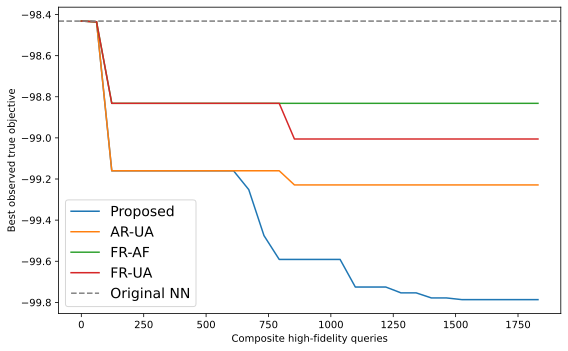

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
budgets = np.arange(max_iterations + 1) * queries_per_iteration
for group in GROUPS:
    history = histories[group]
    initial = float(history.loc[0, 'F_current'])
    observed = np.minimum(history['F_current'].to_numpy(float),
                          history['F_candidate'].to_numpy(float))
    best = np.minimum.accumulate(np.r_[initial, observed])
    if len(history) < max_iterations:
        best = np.pad(best, (0, max_iterations + 1 - len(best)), mode='edge')
    ax.plot(budgets, best, label=LABELS[group], color=COLORS[group])
ax.axhline(baseline, color='gray', linestyle='--',
           label='Original NN')
ax.set(xlabel='Composite high-fidelity queries',
       ylabel='Best observed true objective')
if BUDGET_YLIM is not None:
    ax.set_ylim(*BUDGET_YLIM)
ax.legend(fontsize=14)
finish_figure(fig, 'best_so_far_by_query')

## 图 2：历史最好值与最终返回点

两种标记相隔越远，说明后续接受候选造成的退化越大；该图不会把被拒绝的候选当作最终返回点。

Saved: results/tr_ablation_seed_42/figures/best_vs_final.pdf


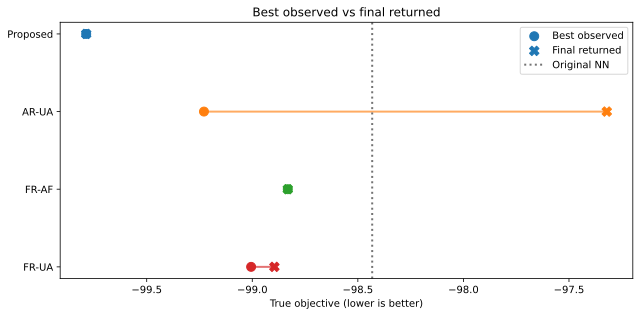

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for row, group in enumerate(GROUPS):
    best = float(metrics.loc[group, 'best_at_budget'])
    final = float(metrics.loc[group, 'final_returned'])
    ax.plot([best, final], [row, row], color=COLORS[group], linewidth=2, alpha=0.65)
    ax.scatter(best, row, color=COLORS[group], s=80, marker='o', zorder=3,
               label='Best observed' if row == 0 else None)
    ax.scatter(final, row, color=COLORS[group], s=90, marker='X', zorder=4,
               label='Final returned' if row == 0 else None)
ax.axvline(baseline, color='0.45', linestyle=':', linewidth=2, label='Original NN')
ax.set_yticks(range(len(GROUPS)), [LABELS[group] for group in GROUPS])
ax.invert_yaxis()
ax.set(xlabel='True objective (lower is better)', title='Best observed vs final returned')
if OBJECTIVE_XLIM is not None:
    ax.set_xlim(*OBJECTIVE_XLIM)
ax.legend(loc='best')
finish_figure(fig, 'best_vs_final')

## 图 3：半径轨迹与实际更新动作

红叉表示真正拒绝；橙色三角表示原规则本应拒绝、但被 `always_accept` 强制接受。半径用对数坐标，方便同时观察固定 0.05 与逐渐缩小的半径。

Saved: results/tr_ablation_seed_42/figures/radius_and_decisions.pdf


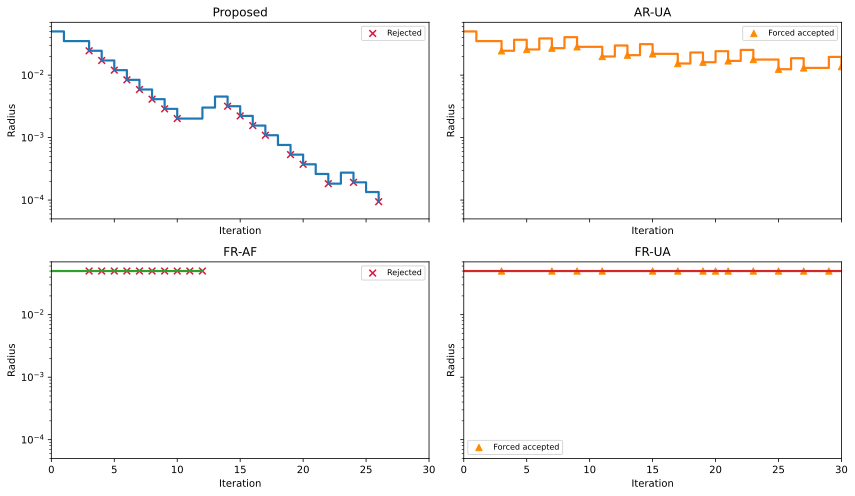

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, group in zip(axes.flat, GROUPS):
    history = histories[group]
    iteration = history['k'].to_numpy(int) + 1
    radius = np.r_[float(history.loc[0, 'R_before']), history['R_after'].to_numpy(float)]
    ax.step(np.r_[0, iteration], radius, where='post',
            color=COLORS[group], linewidth=2.2)
    rejected = history['decision'].eq('reject').to_numpy()
    forced = history['decision'].eq('accept_forced_shrink').to_numpy()
    if rejected.any():
        ax.scatter(iteration[rejected], radius[1:][rejected], color='crimson',
                   marker='x', s=45, label='Rejected')
    if forced.any():
        ax.scatter(iteration[forced], radius[1:][forced], color='darkorange',
                   marker='^', s=40, label='Forced accepted')
    ax.set(title=LABELS[group], xlim=(0, max_iterations), ylim=RADIUS_YLIM,
           yscale='log', xlabel='Iteration', ylabel='Radius')
    if rejected.any() or forced.any():
        ax.legend(fontsize=8, loc='best')
finish_figure(fig, 'radius_and_decisions')

## 图 4：候选点的 surrogate 预测误差

这里画的是每轮候选点的 `|F_candidate - F_tilde_candidate|`，用于诊断局部模型，不是优化目标。

Saved: results/tr_ablation_seed_42/figures/candidate_prediction_error.pdf


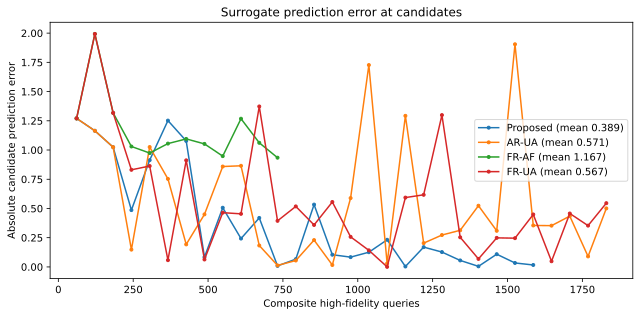

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for group in GROUPS:
    history = histories[group]
    error = (history['F_candidate'] - history['F_tilde_candidate']).abs()
    budget = (history['k'] + 1) * queries_per_iteration
    ax.plot(budget, error, '-o', markersize=3, linewidth=1.5,
            color=COLORS[group], label=f'{LABELS[group]} (mean {error.mean():.3f})')
ax.set(xlabel='Composite high-fidelity queries',
       ylabel='Absolute candidate prediction error',
       title='Surrogate prediction error at candidates')
if ERROR_YLIM is not None:
    ax.set_ylim(*ERROR_YLIM)
ax.legend()
finish_figure(fig, 'candidate_prediction_error')

## 图 5：四组的 `F_next` 迭代轨迹

横轴为迭代轮次（从 1 开始，对应原始记录中的 `k+1`），纵轴为该轮更新后的真实目标值：接受时取候选点，拒绝时保持当前点。提前停止后没有新的 `F_next`，因此这里不向后填充。

Saved: results/tr_ablation_seed_42/figures/f_next_by_iteration.pdf


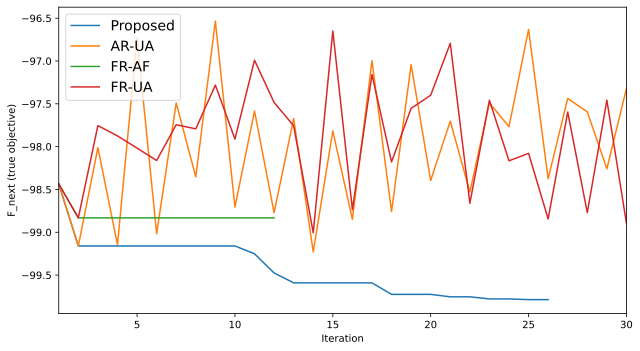

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for group in GROUPS:
    history = histories[group]
    ax.plot(history['k'] + 1, history['F_next'],
            label=LABELS[group], color=COLORS[group])
ax.set(xlabel='Iteration', ylabel='F_next (true objective)',
       xlim=(1, max_iterations))
if F_NEXT_YLIM is not None:
    ax.set_ylim(*F_NEXT_YLIM)
ax.legend(fontsize=14)
finish_figure(fig, 'f_next_by_iteration')

## 修改与复用

- 换实验：修改首个代码格的 `SEED`，然后重新运行所有格。
- 换配色、坐标范围：修改首个代码格；改曲线、标题和标记：修改对应图的代码格。
- 五张图只保存为 PDF，位于 `results/tr_ablation_seed_<SEED>/figures/`；不会覆盖运行 notebook 生成的 `budget_curves.pdf`。
- 只有一个 seed 时这些图是描述性结果，不能用作显著性证据。